# 02 · Geografija: kje je IT rastel in kje upadal po letu 2019?

V tem zvezku pogledamo ameriška mestna območja in vprašamo: **kje je IT rastel hitreje, kje počasneje, in zakaj?**

**Kaj pomeni »IT« tukaj:** panogo 5415 (NAICS), torej *IT svetovanje in pogodbene storitve*: podjetja, ki drugim pišejo programe, načrtujejo sisteme in upravljajo računalniško opremo. **Niso** zajeta podjetja, ki prodajajo lastne izdelke (na primer Google ali Microsoft).

**Dva načina merjenja (ker nam podatki včasih manjkajo):**
- **A. Delovna mesta v IT.** Boljša mera, a ameriški statistični urad za nekatera mesta (na primer Chicago, Houston, Atlanta) podatka ne objavi, da ne bi razkril posameznih podjetij.
- **B. Število podjetij oziroma poslovnih enot v IT.** Objavljeno je za skoraj vsa mesta, a šteje kraje, ne ljudi.

**Kako merimo rast:** v »logaritemskih točkah« (100 × ln(2024/2019)). To je skoraj isto kot odstotki, le da majhna mesta z majhnimi številkami ne popačijo slike. **Koeficienti** v grafih povedo, za koliko se rast spremeni, če je napovedovalec za en standardni odklon višji (en standardni odklon je tipična razlika med mesti).

Podatki so v `data/processed/metro_panel.csv`; ustvari ga `python build_metro_panel.py`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
import sys; sys.path.insert(0, str(ROOT))
from analysis import metro_models as mm

FIG = ROOT / "reports" / "figures_sl"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold"})
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def sl(x, nd=0, sign=False):
    """slovensko oblikovanje števil: tisočice s piko, decimalke z vejico (2.509 ; -5,6)"""
    t = f"{x:+,.{nd}f}" if sign else f"{x:,.{nd}f}"
    return t.replace(",", "X").replace(".", ",").replace("X", ".")

OZNAKE = {  # slovenska imena napovedovalcev
    "log_it_emp": "IT delovna mesta 2019 (log)", "preA": "Rast IT delovnih mest 2015–19", "log_lq": "Koncentracija IT (log)",
    "log_estab_size": "Povprečna velikost IT enote (log)", "log_size": "Vsa zaposlenost (log)",
    "preB": "Rast števila IT podjetij 2015–19", "log_eq": "Gostota IT podjetij (log)",
    "wfh_share_pct_acs2019": "Delež dela od doma 2019", "wfh_change_pp": "Sprememba deleža dela od doma (odst. točke)",
    "bachelors_plus_pct_acs2019": "Delež z univerzitetno izobrazbo (%)", "log_pop": "Prebivalstvo (log)",
    "log_inc": "Mediana dohodka gospodinjstev (log)", "log_rent": "Mediana najemnine (log)",
    "median_age_acs2019": "Mediana starosti", "hpi_growth_pre_pct": "Rast cen stanovanj 2015–19",
    "hpi_growth_pct": "Rast cen stanovanj 2019–24",
}

p = mm.prepare(pd.read_csv(ROOT / "data" / "processed" / "metro_panel.csv", dtype={"cbsa_code": str}))
p["metro"] = p["metro_name"].fillna(p["cbsa_code"]).str.replace(r" Metro Area", "", regex=True)
vsi = p["emp_total_2019"]; velika = p.loc[vsi.nlargest(25).index]
pokritost = pd.DataFrame({
    "število mest": [int(p.usable.sum()), int(p.usable_estab.sum())],
    "delež vseh zaposlenih": [vsi[p.usable].sum() / vsi.sum(), vsi[p.usable_estab].sum() / vsi.sum()],
    "od 25 največjih": [int(velika.usable.sum()), int(velika.usable_estab.sum())],
    "mediana rasti 2019–24 (%)": [p.loc[p.usable, "it_growth_pct"].median(), p.loc[p.usable_estab, "estab_growth_pct"].median()],
}, index=["A. IT delovna mesta", "B. IT podjetja"])
pokritost.style.format({"delež vseh zaposlenih": "{:.0%}", "mediana rasti 2019–24 (%)": "{:.1f}"})

,število mest,delež vseh zaposlenih,od 25 največjih,mediana rasti 2019–24 (%)
A. IT delovna mesta,258,70%,20,12.6
B. IT podjetja,372,99%,25,44.5


## 1 · Največja mesta: ali se oba načina merjenja ujemata?

Vsaka vrstica je eno od 25 največjih mest (po vseh zaposlenih). **Modra pika** je rast delovnih mest v IT, **oranžna** pa rast števila IT podjetij. Če modre pike ni, je podatek o delovnih mestih skrit. Siva črta povezuje obe meritvi.

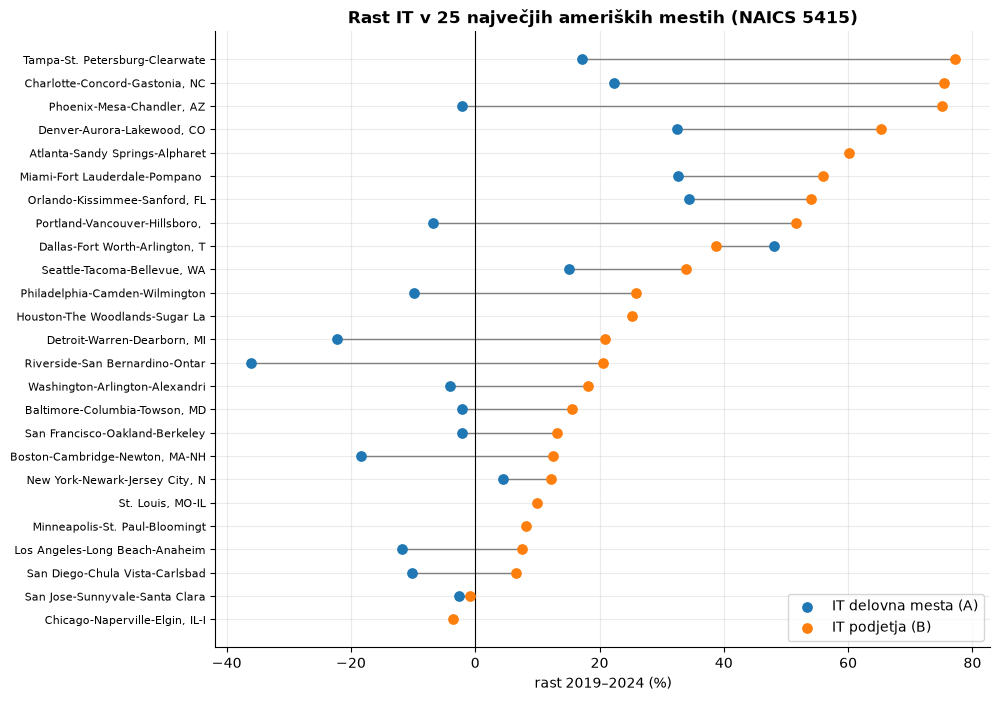

In [2]:
b = velika.sort_values("estab_growth_pct").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 8))
for i, r in b.iterrows():
    if pd.notna(r.it_growth_pct): ax.plot([r.it_growth_pct, r.estab_growth_pct], [i, i], color="grey", lw=1)
ax.scatter(b.it_growth_pct, b.index, color="tab:blue", s=45, label="IT delovna mesta (A)", zorder=3)
ax.scatter(b.estab_growth_pct, b.index, color="tab:orange", s=45, label="IT podjetja (B)", zorder=3)
ax.set_yticks(b.index); ax.set_yticklabels(b.metro.str.slice(0, 30), fontsize=8)
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("rast 2019–2024 (%)"); ax.legend(loc="lower right")
ax.set_title("Rast IT v 25 največjih ameriških mestih (NAICS 5415)")
save(fig, "10_velika_mesta"); plt.show()

## 2 · Vpliv velikosti: majhna mesta in velike enote

Majhne številke zelo nihajo, zato majhna mesta pogosto kažejo velike odstotke rasti. Poleg tega so mesta, kjer so bile IT enote leta 2019 večje, rasla počasneje. Vsaka pika je eno mesto, rdeča črta je mediana po skupinah mest.

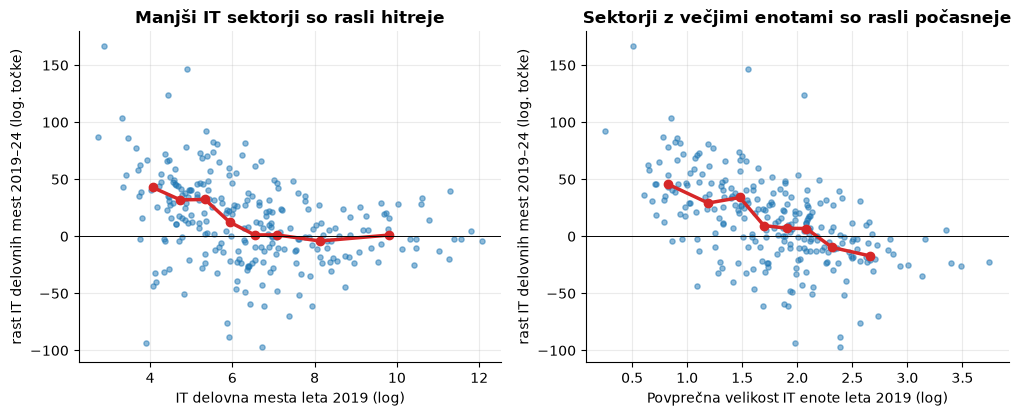

Korelacija rasti z velikostjo IT sektorja: -0,34
Korelacija rasti z povprečno velikostjo IT enote: -0,55


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
a = p[p.usable]
for ax, x, xl in [(axs[0], "log_it_emp", "IT delovna mesta leta 2019 (log)"), (axs[1], "log_estab_size", "Povprečna velikost IT enote leta 2019 (log)")]:
    ax.scatter(a[x], a["yA"], s=14, alpha=0.5)
    g = a.assign(skupina=pd.qcut(a[x], 8)).groupby("skupina", observed=True).agg(x=(x, "median"), y=("yA", "median"))
    ax.plot(g.x, g.y, color="tab:red", lw=2.5, marker="o"); ax.axhline(0, color="black", lw=0.7)
    ax.set_xlabel(xl); ax.set_ylabel("rast IT delovnih mest 2019–24 (log. točke)")
axs[0].set_title("Manjši IT sektorji so rasli hitreje"); axs[1].set_title("Sektorji z večjimi enotami so rasli počasneje")
save(fig, "11_velikost"); plt.show()
for k, ime in [("log_it_emp", "velikostjo IT sektorja"), ("log_estab_size", "povprečno velikostjo IT enote")]:
    print(f"Korelacija rasti z {ime}: {sl(a[['yA', k]].corr().iloc[0, 1], 2)}")

## 3 · Kaj napoveduje rast? Regresija s preizkusom na novih mestih

Vsaka vodoravna črta kaže, kolikšen vpliv ima en dejavnik na rast. **Rdeče** je tisto, kar zanesljivo odstopa od nič; **sivo** je tisto, kjer ne moremo biti prepričani. Črtice na koncu so interval zaupanja: če prečka ničlo, vpliva ne moremo potrditi.

Nad vsakim grafom sta dve števili. **R²** pove, koliko razlik med mesti model razloži na podatkih, na katerih se je učil. **CV R²** pa isto na mestih, ki jih model *ni videl*, in je pošteno število. Če je blizu nič, model ni boljši od ugibanja povprečja.

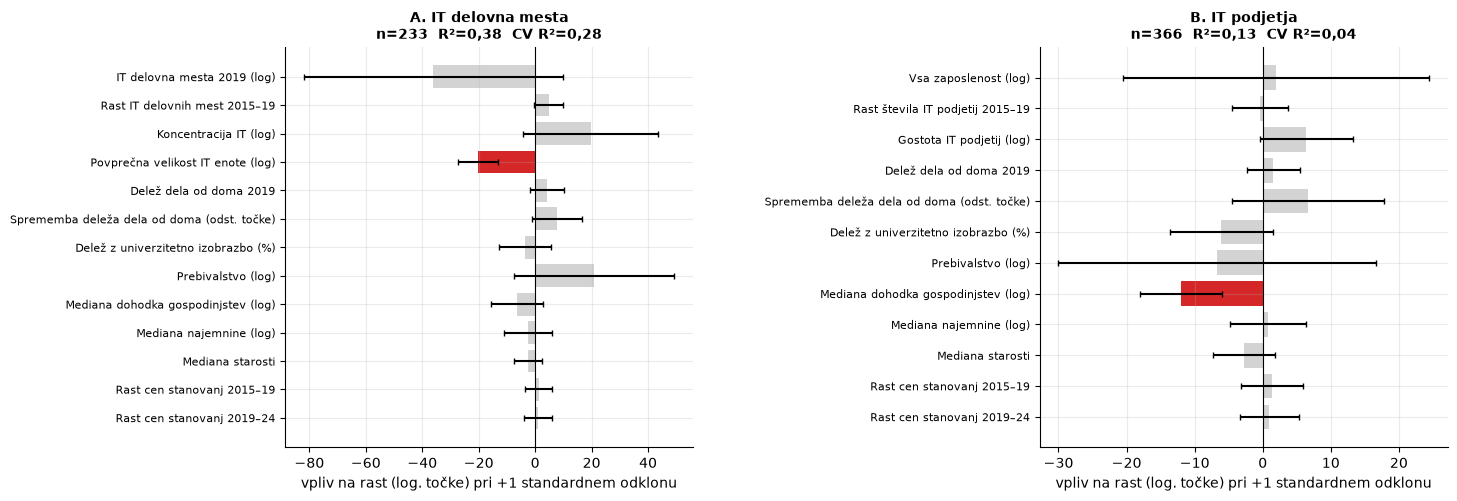

A: zanesljivo (95 %) vpliva: ['Povprečna velikost IT enote (log)']
B: zanesljivo (95 %) vpliva: ['Mediana dohodka gospodinjstev (log)']


In [4]:
rez = {w: mm.run(p, w) for w in ("A", "B")}
fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"wspace": 0.85})
for ax, w, naslov in [(axs[0], "A", "A. IT delovna mesta"), (axs[1], "B", "B. IT podjetja")]:
    r = rez[w]; t = r["table"].iloc[::-1]
    zanesljivo = (t.ci_lo > 0) | (t.ci_hi < 0)
    ax.barh([OZNAKE[i] for i in t.index], t.coef, xerr=[t.coef - t.ci_lo, t.ci_hi - t.coef],
            color=["tab:red" if s else "lightgrey" for s in zanesljivo], ecolor="black", capsize=2)
    ax.axvline(0, color="black", lw=0.8); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"{naslov}\nn={r['n']}  R²={sl(r['r2'], 2)}  CV R²={sl(r['cv_mean'], 2)}", fontsize=10)
    ax.set_xlabel("vpliv na rast (log. točke) pri +1 standardnem odklonu")
save(fig, "12_koeficienti"); plt.show()
for w in rez:
    t = rez[w]["table"]
    zan = [OZNAKE[i] for i in t.index if (t.loc[i, "ci_lo"] > 0) or (t.loc[i, "ci_hi"] < 0)]
    print(f"{w}: zanesljivo (95 %) vpliva:", zan if zan else "nič")

## 4 · Delo od doma: ali so večji skoki dela na daljavo pomenili slabšo rast IT?

Vsaka pika je eno mesto. Na vodoravni osi je, za koliko odstotnih točk se je delež ljudi, ki delajo od doma, povečal (primerjava obdobij 2015–2019 in 2020–2024, podatki ameriškega popisa), na navpični pa rast IT.

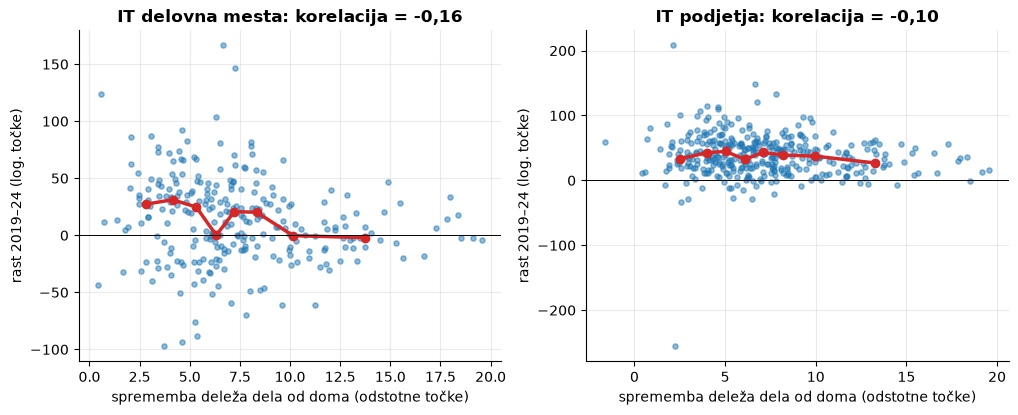

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, w, y, naslov in [(axs[0], "A", "yA", "IT delovna mesta"), (axs[1], "B", "yB", "IT podjetja")]:
    d = p[p[mm.SUBSET_COL[w]]].dropna(subset=["wfh_change_pp", y])
    ax.scatter(d.wfh_change_pp, d[y], s=14, alpha=0.5)
    g = d.assign(skupina=pd.qcut(d.wfh_change_pp, 8)).groupby("skupina", observed=True).agg(x=("wfh_change_pp", "median"), y=(y, "median"))
    ax.plot(g.x, g.y, color="tab:red", lw=2.5, marker="o"); ax.axhline(0, color="black", lw=0.7)
    ax.set_xlabel("sprememba deleža dela od doma (odstotne točke)"); ax.set_ylabel("rast 2019–24 (log. točke)")
    ax.set_title(f"{naslov}: korelacija = {sl(d[['wfh_change_pp', y]].corr().iloc[0, 1], 2)}")
save(fig, "13_delo_od_doma"); plt.show()

## Kaj nam to pove in česa ne

**Dokaj trdno:**
- Kjer podatki obstajajo, je rast **delovnih mest** v IT deloma predvidljiva: model razloži približno četrtino do tretjino razlik med mesti, ki jih ni videl.
- Edini napovedovalec, ki zdrži strog preizkus, je **povprečna velikost IT enote**: mesta, kjer so bile IT enote leta 2019 večje, so rasla počasneje.
- Mesta na jugu in v gorskih državah (Dallas, Denver, Miami, Orlando, Tampa, Charlotte) so rasla pri **obeh** merah. Več starejših središč (Boston, Detroit, Los Angeles, Filadelfija, San Diego) pa je izgubilo delovna mesta, čeprav so še dodajala podjetja.

**Šibko ali nedokazano:**
- Rast **števila podjetij** je skoraj nepredvidljiva (CV R² blizu nič). Edini zanesljiv napovedovalec je **mediana dohodka gospodinjstev**: bogatejša mesta so dodala manj IT podjetij. Podjetij je veliko drobnih, zato so številke nemirne.
- Več napovedovalcev velikosti (IT delovna mesta, prebivalstvo, koncentracija IT) se giblje skupaj, zato so njihove posamične črtice široke. Beri jih kot skupino.
- Povezava z delom od doma je šibka. To **ne** dokazuje, da delo na daljavo ni imelo učinka: IT delavci ga uvedejo lažje, zato je lahko smer vzročnosti obrnjena.

**Česa ne moremo trditi:**
- »IT« je tukaj samo panoga 5415. Založniki programske opreme in veliki tehnološki izdelovalci niso zajeti.
- Pet od 25 največjih mest (Chicago, Houston, Atlanta, Minneapolis, St. Louis) nima podatka o IT delovnih mestih; pojavijo se samo pri meri B.
- To so povezave med mesti, ne vzroki.

*Točna števila se lahko ob novem zagonu z novejšimi podatki nekoliko spremenijo.*